<p style="text-align:center">
    <a href="https://skills.network" target="_blank">
    <img src="https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/assets/logos/SN_web_lightmode.png" width="200" alt="Skills Network Logo"  />
    </a>
</p>


# **Data Wrangling Lab**


Estimated time needed: **45** minutes


In this lab, you will perform data wrangling tasks to prepare raw data for analysis. Data wrangling involves cleaning, transforming, and organizing data into a structured format suitable for analysis. This lab focuses on tasks like identifying inconsistencies, encoding categorical variables, and feature transformation.


## Objectives


After completing this lab, you will be able to:


- Identify and remove inconsistent data entries.

- Encode categorical variables for analysis.

- Handle missing values using multiple imputation strategies.

- Apply feature scaling and transformation techniques.


#### Intsall the required libraries


In [1]:
!pip install pandas
!pip install matplotlib

## Tasks


#### Step 1: Import the necessary module.


### 1. Load the Dataset


<h5>1.1 Import necessary libraries and load the dataset.</h5>


Ensure the dataset is loaded correctly by displaying the first few rows.


In [2]:
# Import necessary libraries
import pandas as pd

# Load the Stack Overflow survey data
dataset_url = "https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/n01PQ9pSmiRX6520flujwQ/survey-data.csv"
df = pd.read_csv(dataset_url)

# Display the first few rows
print(df.head())


   ResponseId                      MainBranch                 Age  \
0           1  I am a developer by profession  Under 18 years old   
1           2  I am a developer by profession     35-44 years old   
2           3  I am a developer by profession     45-54 years old   
3           4           I am learning to code     18-24 years old   
4           5  I am a developer by profession     18-24 years old   

            Employment RemoteWork   Check  \
0  Employed, full-time     Remote  Apples   
1  Employed, full-time     Remote  Apples   
2  Employed, full-time     Remote  Apples   
3   Student, full-time        NaN  Apples   
4   Student, full-time        NaN  Apples   

                                    CodingActivities  \
0                                              Hobby   
1  Hobby;Contribute to open-source projects;Other...   
2  Hobby;Contribute to open-source projects;Other...   
3                                                NaN   
4                                 

#### 2. Explore the Dataset


<h5>2.1 Summarize the dataset by displaying the column data types, counts, and missing values.</h5>


In [3]:
# Display column data types, counts, and missing values
df.info()

print("\nMissing values:")
print(df.isnull().sum())

<class 'pandas.DataFrame'>
RangeIndex: 65437 entries, 0 to 65436
Columns: 114 entries, ResponseId to JobSat
dtypes: float64(13), int64(1), str(100)
memory usage: 195.7 MB

Missing values:
ResponseId                 0
MainBranch                 0
Age                        0
Employment                 0
RemoteWork             10631
                       ...  
JobSatPoints_11        35992
SurveyLength            9255
SurveyEase              9199
ConvertedCompYearly    42002
JobSat                 36311
Length: 114, dtype: int64

<h5>2.2 Generate basic statistics for numerical columns.</h5>


In [4]:
df.describe()

,ResponseId,CompTotal,WorkExp,JobSatPoints_1,JobSatPoints_4,JobSatPoints_5,JobSatPoints_6,JobSatPoints_7,JobSatPoints_8,JobSatPoints_9,JobSatPoints_10,JobSatPoints_11,ConvertedCompYearly,JobSat
count,65437.000000,3.374000e+04,29658.000000,29324.000000,29393.000000,29411.000000,29450.000000,29448.00000,29456.000000,29456.000000,29450.000000,29445.000000,2.343500e+04,29126.000000
mean,32719.000000,2.963841e+145,11.466957,18.581094,7.522140,10.060857,24.343232,22.96522,20.278165,16.169432,10.955713,9.953948,8.615529e+04,6.935041
std,18890.179119,5.444117e+147,9.168709,25.966221,18.422661,21.833836,27.089360,27.01774,26.108110,24.845032,22.906263,21.775652,1.867570e+05,2.088259
min,1.000000,0.000000e+00,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000,0.000000,1.000000e+00,0.000000
25%,16360.000000,6.000000e+04,4.000000,0.000000,0.000000,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000,0.000000,3.271200e+04,6.000000
50%,32719.000000,1.100000e+05,9.000000,10.000000,0.000000,0.000000,20.000000,15.00000,10.000000,5.000000,0.000000,0.000000,6.500000e+04,7.000000
75%,49078.000000,2.500000e+05,16.000000,22.000000,5.000000,10.000000,30.000000,30.00000,25.000000,20.000000,10.000000,10.000000,1.079715e+05,8.000000
max,65437.000000,1.000000e+150,50.000000,100.000000,100.000000,100.000000,100.000000,100.00000,100.000000,100.000000,100.000000,100.000000,1.625660e+07,10.000000


### 3. Identifying and Removing Inconsistencies


<h5>3.1 Identify inconsistent or irrelevant entries in specific columns (e.g., Country).</h5>


In [5]:
# Display country names
print(df['Country'].unique())

<ArrowStringArray>
[                            'United States of America',
 'United Kingdom of Great Britain and Northern Ireland',
                                               'Canada',
                                               'Norway',
                                           'Uzbekistan',
                                               'Serbia',
                                               'Poland',
                                          'Philippines',
                                             'Bulgaria',
                                          'Switzerland',
 ...
                                'Saint Kitts and Nevis',
                                               'Monaco',
                   'Micronesia, Federated States of...',
                                                'Haiti',
                                                    nan,
                                                'Nauru',
                                              'Liberia',
       

<h5>3.2 Standardize entries in columns like Country or EdLevel by mapping inconsistent values to a consistent format.</h5>


In [9]:
df['Country'].value_counts()
df['EdLevel'].value_counts()

print(df['EdLevel'].unique())


<ArrowStringArray>
[                                                         'Primary/elementary school',
                                       'Bachelor’s degree (B.A., B.S., B.Eng., etc.)',
                                    'Master’s degree (M.A., M.S., M.Eng., MBA, etc.)',
                             'Some college/university study without earning a degree',
 'Secondary school (e.g. American high school, German Realschule or Gymnasium, etc.)',
                                     'Professional degree (JD, MD, Ph.D, Ed.D, etc.)',
                                                'Associate degree (A.A., A.S., etc.)',
                                                                     'Something else',
                                                                                  nan]
Length: 9, dtype: str

### 4. Encoding Categorical Variables


<h5>4.1 Encode the Employment column using one-hot encoding.</h5>


In [10]:
# One-hot encode the Employment column
df = pd.get_dummies(df, columns=['Employment'], prefix='Employment')

df.head()

,ResponseId,MainBranch,Age,RemoteWork,Check,CodingActivities,EdLevel,LearnCode,LearnCodeOnline,TechDoc,...,"Employment_Student, full-time;Not employed, but looking for work;Not employed, and not looking for work;Student, part-time","Employment_Student, full-time;Not employed, but looking for work;Retired","Employment_Student, full-time;Not employed, but looking for work;Student, part-time","Employment_Student, full-time;Retired","Employment_Student, full-time;Student, part-time","Employment_Student, full-time;Student, part-time;Employed, part-time","Employment_Student, full-time;Student, part-time;Retired","Employment_Student, part-time","Employment_Student, part-time;Employed, part-time","Employment_Student, part-time;Retired"
0,1,I am a developer by profession,Under 18 years old,Remote,Apples,Hobby,Primary/elementary school,Books / Physical media,NaN,NaN,...,False,False,False,False,False,False,False,False,False,False
1,2,I am a developer by profession,35-44 years old,Remote,Apples,Hobby;Contribute to open-source projects;Other...,"Bachelor’s degree (B.A., B.S., B.Eng., etc.)",Books / Physical media;Colleague;On the job tr...,Technical documentation;Blogs;Books;Written Tu...,API document(s) and/or SDK document(s);User gu...,...,False,False,False,False,False,False,False,False,False,False
2,3,I am a developer by profession,45-54 years old,Remote,Apples,Hobby;Contribute to open-source projects;Other...,"Master’s degree (M.A., M.S., M.Eng., MBA, etc.)",Books / Physical media;Colleague;On the job tr...,Technical documentation;Blogs;Books;Written Tu...,API document(s) and/or SDK document(s);User gu...,...,False,False,False,False,False,False,False,False,False,False
3,4,I am learning to code,18-24 years old,NaN,Apples,NaN,Some college/university study without earning ...,"Other online resources (e.g., videos, blogs, f...",Stack Overflow;How-to videos;Interactive tutorial,NaN,...,False,False,False,False,False,False,False,False,False,False
4,5,I am a developer by profession,18-24 years old,NaN,Apples,NaN,"Secondary school (e.g. American high school, G...","Other online resources (e.g., videos, blogs, f...",Technical documentation;Blogs;Written Tutorial...,API document(s) and/or SDK document(s);User gu...,...,False,False,False,False,False,False,False,False,False,False


### 5. Handling Missing Values


<h5>5.1 Identify columns with the highest number of missing values.</h5>


In [11]:
# Count missing values in each column
missing_values = df.isnull().sum()

# Sort from highest to lowest
missing_values = missing_values.sort_values(ascending=False)

missing_values

AINextMuch less integrated                                              64289
AINextLess integrated                                                   63082
AINextNo change                                                         52939
AINextMuch more integrated                                              51999
EmbeddedAdmired                                                         48704
                                                                        ...  
Employment_Student, full-time;Student, part-time;Employed, part-time        0
Employment_Student, full-time;Student, part-time;Retired                    0
Employment_Student, part-time                                               0
Employment_Student, part-time;Employed, part-time                           0
Employment_Student, part-time;Retired                                       0
Length: 223, dtype: int64

<h5>5.2 Impute missing values in numerical columns (e.g., `ConvertedCompYearly`) with the mean or median.</h5>


In [12]:
mean_value = df['ConvertedCompYearly'].mean()

df['ConvertedCompYearly'] = df['ConvertedCompYearly'].fillna(mean_value)

print("Missing values after imputation:", df['ConvertedCompYearly'].isnull().sum())

Missing values after imputation: 0

<h5>5.3 Impute missing values in categorical columns (e.g., `RemoteWork`) with the most frequent value.</h5>


In [13]:
most_frequent = df['RemoteWork'].mode()[0]

df['RemoteWork'] = df['RemoteWork'].fillna(most_frequent)

print("Most frequent value:", most_frequent)
print("Missing values after imputation:", df['RemoteWork'].isnull().sum())

Most frequent value: Hybrid (some remote, some in-person)
Missing values after imputation: 0

### 6. Feature Scaling and Transformation


<h5>6.1 Apply Min-Max Scaling to normalize the `ConvertedCompYearly` column.</h5>


In [15]:
df['ConvertedCompYearly_Normalized'] = (
    (df['ConvertedCompYearly'] - df['ConvertedCompYearly'].min()) /
    (df['ConvertedCompYearly'].max() - df['ConvertedCompYearly'].min())
)

df[['ConvertedCompYearly', 'ConvertedCompYearly_Normalized']].head()

,ConvertedCompYearly,ConvertedCompYearly_Normalized
0,86155.287263,0.0053
1,86155.287263,0.0053
2,86155.287263,0.0053
3,86155.287263,0.0053
4,86155.287263,0.0053


<h5>6.2 Log-transform the ConvertedCompYearly column to reduce skewness.</h5>


In [16]:
import numpy as np

df['ConvertedCompYearly_Log'] = np.log1p(df['ConvertedCompYearly'])

df[['ConvertedCompYearly', 'ConvertedCompYearly_Log']].head()

,ConvertedCompYearly,ConvertedCompYearly_Log
0,86155.287263,11.363918
1,86155.287263,11.363918
2,86155.287263,11.363918
3,86155.287263,11.363918
4,86155.287263,11.363918


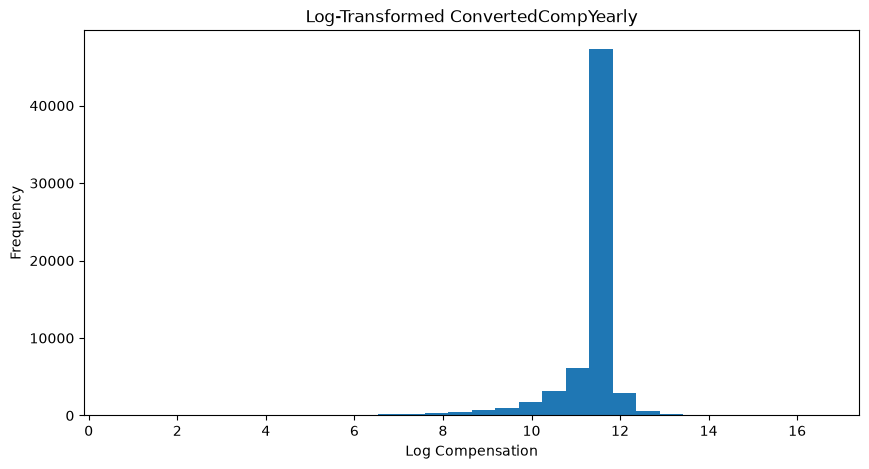

In [17]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))
plt.hist(df['ConvertedCompYearly_Log'].dropna(), bins=30)
plt.title('Log-Transformed ConvertedCompYearly')
plt.xlabel('Log Compensation')
plt.ylabel('Frequency')
plt.show()

### 7. Feature Engineering


<h5>7.1 Create a new column `ExperienceLevel` based on the `YearsCodePro` column:</h5>


In [19]:
import pandas as pd
import numpy as np

# Convert YearsCodePro to numeric
df['YearsCodePro_numeric'] = pd.to_numeric(
    df['YearsCodePro'], errors='coerce'
)

# Create ExperienceLevel
df['ExperienceLevel'] = np.select(
    [
        df['YearsCodePro_numeric'] < 3,
        df['YearsCodePro_numeric'].between(3, 7),
        df['YearsCodePro_numeric'] > 7
    ],
    [
        'Entry',
        'Mid',
        'Senior'
    ],
    default='Unknown'
)

df[['YearsCodePro', 'ExperienceLevel']].head()

,YearsCodePro,ExperienceLevel
0,NaN,Unknown
1,17,Senior
2,27,Senior
3,NaN,Unknown
4,NaN,Unknown


### Summary


In this lab, you:

- Explored the dataset to identify inconsistencies and missing values.

- Encoded categorical variables for analysis.

- Handled missing values using imputation techniques.

- Normalized and transformed numerical data to prepare it for analysis.

- Engineered a new feature to enhance data interpretation.


Copyright © IBM Corporation. All rights reserved.
